# 09 · Componentes mecánicos auxiliares

Exploraremos la ley de Hooke, la suma de fuerzas colineales y los desplazamientos brownianos. Estas utilidades todavía no están acopladas al motor de Gillespie.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from protein_motor_sim.mechanics.elasticity import HookeanSpring
from protein_motor_sim.mechanics.forces import Force, net_force
from protein_motor_sim.mechanics.brownian import brownian_displacement

## 1. Resorte lineal

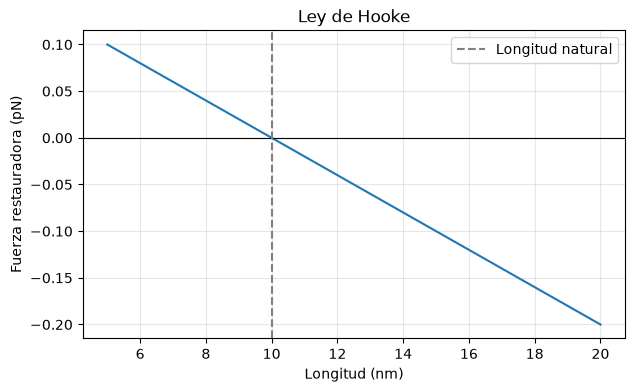

In [3]:
spring = HookeanSpring(stiffness_N_m=2.0e-5, rest_length_m=10.0e-9)
lengths_m = np.linspace(5e-9, 20e-9, 100)
forces_pN = np.array([spring.force_N(length) for length in lengths_m]) * 1e12

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(lengths_m * 1e9, forces_pN)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(spring.rest_length_m * 1e9, color="gray", linestyle="--", label="Longitud natural")
ax.set(xlabel="Longitud (nm)", ylabel="Fuerza restauradora (pN)", title="Ley de Hooke")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 2. Suma de fuerzas

In [4]:
motor_force = Force(3.0e-12, label="motor")
load_force = Force(-5.0e-12, label="load")
resultant = net_force(motor_force, load_force)
print(f"Fuerza resultante: {resultant.value_N * 1e12:.2f} pN")

Fuerza resultante: -2.00 pN


## 3. Distribución de incrementos brownianos

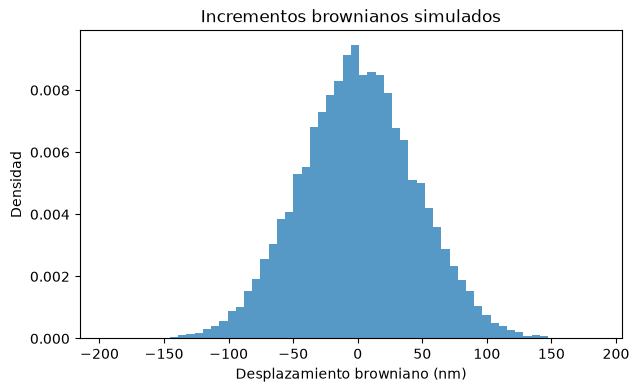

Desviación estándar observada: 44.933 nm
Desviación estándar teórica:  44.721 nm


In [5]:
rng = np.random.default_rng(42)
D_m2_s = 1.0e-12
dt_s = 1.0e-3
samples_m = np.array([
    brownian_displacement(D_m2_s, dt_s, rng)
    for _ in range(20_000)
])
samples_nm = samples_m * 1e9
expected_std_nm = np.sqrt(2 * D_m2_s * dt_s) * 1e9

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(samples_nm, bins=60, density=True, alpha=0.75, edgecolor="none")
ax.set_xlabel("Desplazamiento browniano (nm)")
ax.set_ylabel("Densidad")
ax.set_title("Incrementos brownianos simulados")
plt.show()
print(f"Desviación estándar observada: {samples_nm.std(ddof=1):.3f} nm")
print(f"Desviación estándar teórica:  {expected_std_nm:.3f} nm")

**Importante:** esta simulación browniana es una utilidad aislada. No describe todavía el movimiento de kinesina ni la dinámica de su carga. Para ello necesitaremos formular y validar un modelo mecánico acoplado.